# Comparação de modelos — NSL-KDD

Execute as células na ordem. **0 = sem ataque; 1 = ataque.**


In [1]:
%pip -q install pandas scikit-learn xgboost matplotlib

## 1. Baixar e preparar o NSL-KDD

In [2]:
from pathlib import Path
from urllib.request import Request, urlopen
import shutil, time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

PASTA = Path('/content/nsl_kdd')
DADOS, SAIDA = PASTA / 'dados', PASTA / 'resultados'
DADOS.mkdir(parents=True, exist_ok=True)
SAIDA.mkdir(parents=True, exist_ok=True)
FONTES = [
    'https://raw.githubusercontent.com/defcom17/NSL_KDD/master/',
    'https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/',
    'https://raw.githubusercontent.com/defcom17/NSL_KDD/main/',
]

def baixar(nome, minimo):
    destino = DADOS / nome
    if destino.exists() and destino.stat().st_size >= minimo:
        return destino
    erros = []
    for fonte in FONTES:
        try:
            url = fonte + nome
            print('Baixando', url)
            req = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urlopen(req, timeout=90) as resposta, open(destino, 'wb') as arquivo:
                shutil.copyfileobj(resposta, arquivo)
            if destino.stat().st_size < minimo or pd.read_csv(destino, header=None, nrows=2).shape[1] != 43:
                raise ValueError('Arquivo incompleto ou formato inválido')
            return destino
        except Exception as erro:
            erros.append(f'{url}: {erro}')
            destino.unlink(missing_ok=True)
    raise RuntimeError('Falha no download automático:\n' + '\n'.join(erros))

colunas = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes','land',
    'wrong_fragment','urgent','hot','num_failed_logins','logged_in','num_compromised',
    'root_shell','su_attempted','num_root','num_file_creations','num_shells',
    'num_access_files','num_outbound_cmds','is_host_login','is_guest_login',
    'count','srv_count','serror_rate','srv_serror_rate','rerror_rate',
    'srv_rerror_rate','same_srv_rate','diff_srv_rate','srv_diff_host_rate',
    'dst_host_count','dst_host_srv_count','dst_host_same_srv_rate',
    'dst_host_diff_srv_rate','dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate','dst_host_serror_rate','dst_host_srv_serror_rate',
    'dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty'
]

def carregar(arquivo):
    df = pd.read_csv(arquivo, names=colunas)
    if df.shape[1] != 43:
        raise ValueError('Formato do NSL-KDD inválido')
    y = (df['label'].astype(str).str.strip().str.rstrip('.') != 'normal').astype(int)
    return df.drop(columns=['label','difficulty']), y

X_treino, y_treino = carregar(baixar('KDDTrain+.txt', 5_000_000))
X_teste, y_teste = carregar(baixar('KDDTest+.txt', 1_000_000))
print(f'Treino: {len(X_treino):,} | Teste: {len(X_teste):,}')


Baixando https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain+.txt
Baixando https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest+.txt
Treino: 125,973 | Teste: 22,544


## 2. Treinar e avaliar

Os três modelos usam os mesmos dados de treino e teste.


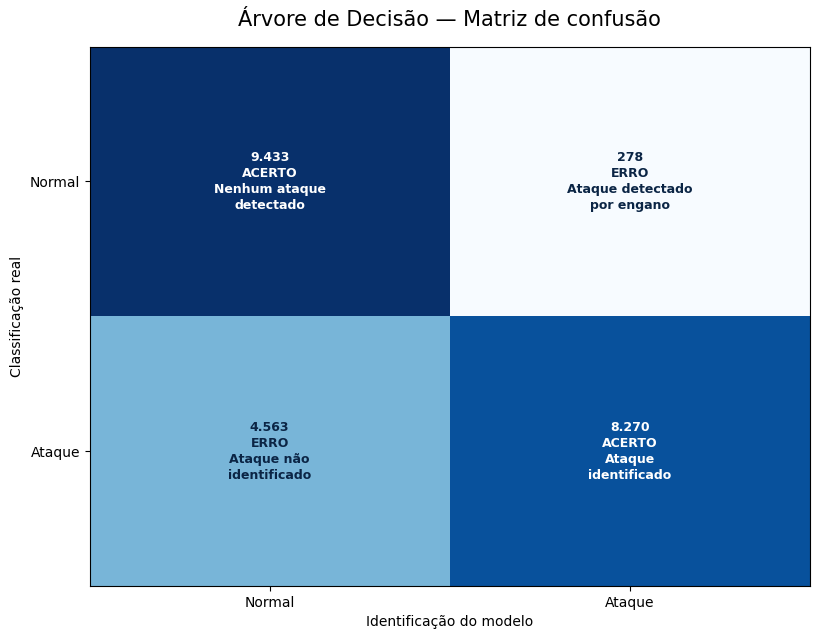

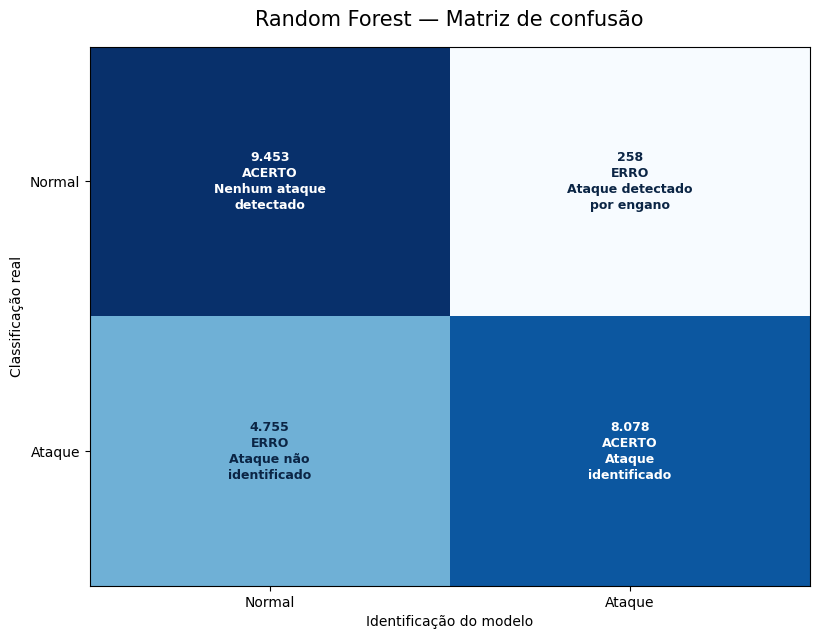

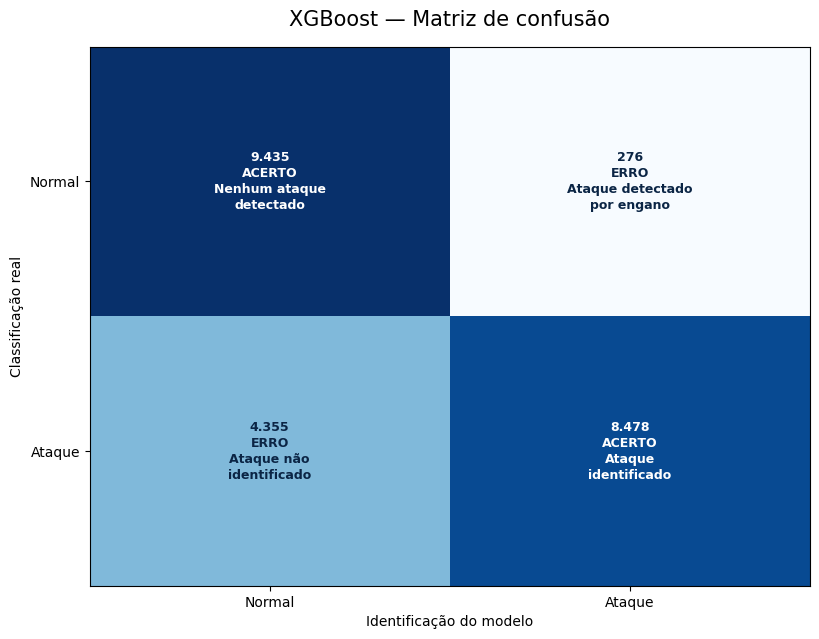

,Modelo,Acurácia,Precisão,Recall,F1-score,Treino (s)
0,Árvore de Decisão,0.7853,0.9675,0.6444,0.7736,6.37
1,Random Forest,0.7776,0.9690,0.6295,0.7632,33.98
2,XGBoost,0.7946,0.9685,0.6606,0.7855,6.31


In [3]:

categoricas = ['protocol_type', 'service', 'flag']
numericas = [c for c in X_treino.columns if c not in categoricas]

modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=12, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.1,
                              eval_metric='logloss', random_state=42, n_jobs=-1),
}

resultados = []
for nome, modelo in modelos.items():
    preparo = ColumnTransformer([
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas),
        ('numericas', 'passthrough', numericas),
    ])
    pipeline = make_pipeline(preparo, modelo)
    inicio = time.perf_counter()
    pipeline.fit(X_treino, y_treino)
    tempo = time.perf_counter() - inicio
    pred = pipeline.predict(X_teste)

    resultados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_teste, pred),
        'Precisão': precision_score(y_teste, pred, zero_division=0),
        'Recall': recall_score(y_teste, pred, zero_division=0),
        'F1-score': f1_score(y_teste, pred, zero_division=0),
        'Treino (s)': round(tempo, 2),
    })

    # Linhas: valor real. Colunas: resultado do modelo.
    matriz = confusion_matrix(y_teste, pred, labels=[0, 1])

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(matriz, cmap='Blues', aspect='auto')

    ax.set_xticks([0, 1], ['Normal', 'Ataque'])
    ax.set_yticks([0, 1], ['Normal', 'Ataque'])
    ax.set_title(f'{nome} — Matriz de confusão', fontsize=15, pad=15)
    ax.set_xlabel('Identificação do modelo')
    ax.set_ylabel('Classificação real')

    descricoes = [
        ['ACERTO\nNenhum ataque\ndetectado',
         'ERRO\nAtaque detectado\npor engano'],
        ['ERRO\nAtaque não\nidentificado',
         'ACERTO\nAtaque\nidentificado']
    ]

    for i in range(2):
        for j in range(2):
            valor = matriz[i, j]
            cor = 'white' if valor > matriz.max() * 0.55 else '#0b2545'
            ax.text(j, i, f'{valor:,}'.replace(',', '.') + '\n' + descricoes[i][j],
                    ha='center', va='center', fontsize=9,
                    color=cor, fontweight='semibold', linespacing=1.3)

    fig.subplots_adjust(left=0.16, right=0.96, top=0.90, bottom=0.13)
    arquivo_nome = (nome.lower().replace(' ', '_')
                    .replace('á', 'a').replace('ã', 'a'))
    fig.savefig(SAIDA / f'{arquivo_nome}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

comparacao = pd.DataFrame(resultados)
comparacao.to_csv(SAIDA / 'comparacao.csv', index=False)
display(comparacao.round(4))


## 3. Comparar os resultados

Os gráficos de métricas ampliam a escala para mostrar diferenças pequenas.


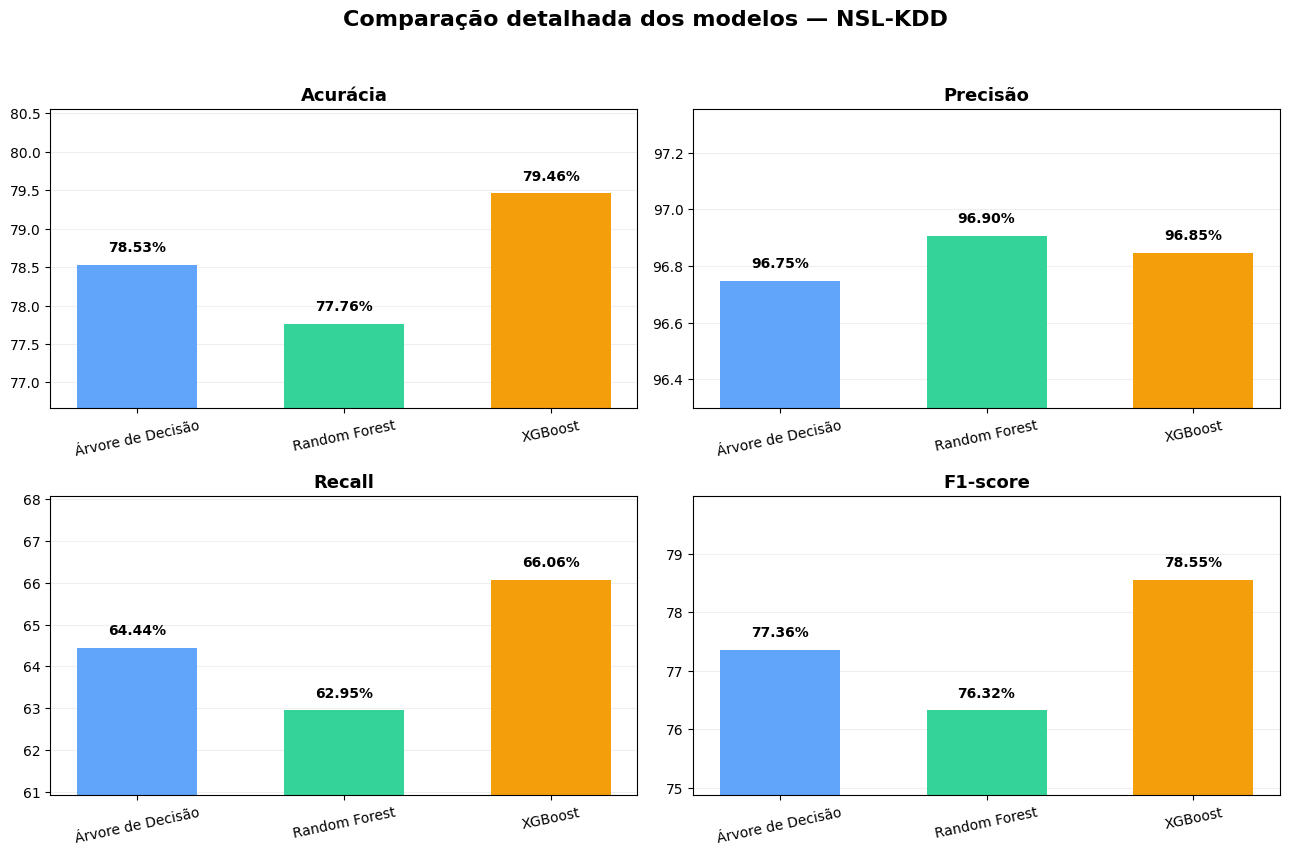

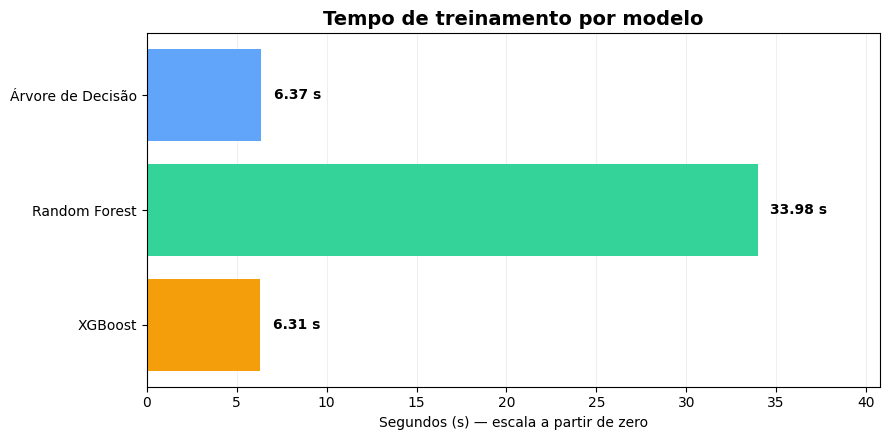

In [4]:

metricas = ['Acurácia', 'Precisão', 'Recall', 'F1-score']
nomes = comparacao['Modelo'].tolist()
cores = ['#60a5fa', '#34d399', '#f59e0b']

fig, eixos = plt.subplots(2, 2, figsize=(13, 9))
for eixo, metrica in zip(eixos.flat, metricas):
    valores = comparacao[metrica].to_numpy(dtype=float) * 100
    minimo, maximo = valores.min(), valores.max()
    margem = max((maximo - minimo) * 0.65, 0.45)
    limite_inf = max(0, minimo - margem)
    limite_sup = min(100, maximo + margem)
    barras = eixo.bar(nomes, valores, color=cores, width=0.58)
    eixo.set_ylim(limite_inf, limite_sup)
    eixo.set_title(metrica, fontsize=13, fontweight='bold')
    eixo.tick_params(axis='x', labelrotation=12)
    eixo.grid(axis='y', alpha=0.2)
    eixo.set_axisbelow(True)
    for barra, valor in zip(barras, valores):
        eixo.text(barra.get_x() + barra.get_width()/2, valor + (limite_sup-limite_inf)*0.035,
                  f'{valor:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
fig.suptitle('Comparação detalhada dos modelos — NSL-KDD', fontsize=16, fontweight='bold')
fig.tight_layout(rect=[0, 0.035, 1, 0.95])
fig.savefig(SAIDA / 'comparacao_detalhada.png', dpi=180, bbox_inches='tight')
plt.show()

fig, eixo = plt.subplots(figsize=(9, 4.5))
tempos = comparacao['Treino (s)'].to_numpy(dtype=float)
barras = eixo.barh(nomes, tempos, color=cores)
eixo.invert_yaxis()
eixo.set_xlim(0, max(tempos) * 1.2)
eixo.set_xlabel('Segundos (s) — escala a partir de zero')
eixo.set_title('Tempo de treinamento por modelo', fontsize=14, fontweight='bold')
eixo.grid(axis='x', alpha=0.2)
eixo.set_axisbelow(True)
for barra, valor in zip(barras, tempos):
    eixo.text(valor + max(tempos)*0.02, barra.get_y() + barra.get_height()/2,
              f'{valor:.2f} s', va='center', fontweight='bold')
fig.tight_layout()
fig.savefig(SAIDA / 'comparacao_tempo.png', dpi=180, bbox_inches='tight')
plt.show()


## 4. Baixar os resultados


In [5]:
arquivo = shutil.make_archive('/content/resultados_nsl_kdd', 'zip', root_dir=SAIDA)
print('Arquivo gerado:', arquivo)
from google.colab import files
files.download(arquivo)

Arquivo gerado: /content/resultados_nsl_kdd.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>